<div class="rqE">

<table width="100%" cellpadding="6"><tr><td bgcolor="#fde9e9"><span style="color:#B71C1C">⚠️ <b>Pay Attention</b></span></td></tr></table>

if you choose a Google Colab cloud session, click on this icon (unless *you are already* in Google Colab):

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rpoteau/pyPhysChem/blob/main/ML-SHAP-MNIST.ipynb)

</div>

In [5]:
import requests

init_url = "https://raw.githubusercontent.com/rpoteau/pyPhysChem/main/colab_init.py"
try:
    r = requests.get(init_url, timeout=5)
    r.raise_for_status()
except requests.exceptions.RequestException:
    print("⚠️ Offline or connection error. Local setup assumed.")
else:
    exec(r.text)
    setup_environment(ML=True,clone_repo=False)

✅ pyphyschemtools is already installed.
to_install=[]
✅ ML packages already available.
🚀 Environment is ready.



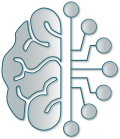

**Environment initialized:** Sunday 22 November 2026, 15:56:04 on 2a01cb1999111b00e470b45a91c945a7.ipv6.abo.wanadoo.fr

pyphyschemtools, release 0.12.8


In [6]:
import pyphyschemtools as t4pPC
from pyphyschemtools import fg, hl, bg, color
t4pPC.init()
%matplotlib inline

__author__ = "Romuald Poteau, LPCNO (INSA-CNRS-UT lab, Toulouse, France)"
print("pyphyschemtools, release",t4pPC.__version__)

# Explaining a CNN with SHAP — the MNIST handwritten digits case

<div class="introE">

<table width="100%" cellpadding="6"><tr><td bgcolor="#e6e6e6"><span style="color:#000000">📖 <b>Introduction</b></span></td></tr></table>

How can we tell *which pixels* a convolutional network actually looks at when it
recognizes a handwritten digit? This notebook applies **SHAP** (SHapley Additive
exPlanations) to CNNs trained on the **MNIST** database of handwritten digits,
and overlays the resulting attribution maps on the images themselves.

It is the companion of the SHAP section of the
[Classification of images notebook](https://github.com/rpoteau/pyPhysChem/blob/main/ML-2DCNN.ipynb).

No data file is needed: MNIST is downloaded by `keras.datasets`.

</div>

## [A] SHAP & Images

<div class="introE">

<table width="100%" cellpadding="6"><tr><td bgcolor="#e6e6e6"><span style="color:#000000">📖 <b>Introduction</b></span></td></tr></table>
    
[see SHAP website](https://shap.readthedocs.io/en/latest/example_notebooks/image_examples/image_classification/Multi-input%20Gradient%20Explainer%20MNIST%20Example.html)
    
Why two inputs?

👉 This is a teaching example from the SHAP website.

- input1: the image is simply flattened into a raw vector (28×28 = 784 pixels).

- input2: the same image goes through a Conv2D layer, which extracts more abstract features.

The two representations (raw pixels + convolutional features) are then concatenated into a single joint vector, which feeds a dense layer and a softmax to predict the class.

In short:

The point is to build a deliberately multi-input model, in order to show that SHAP can explain models that take several inputs.   
</div>


### [A.1] Trial and tuning

In [7]:
import tensorflow as tf
from tensorflow.keras import Input
from tensorflow.keras.layers import Conv2D, Dense, Dropout, Flatten

# load the MNIST data
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0
x_train = x_train.astype("float32")
x_test = x_test.astype("float32")
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1)
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1)


print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

# define our model
input1 = Input(shape=(28, 28, 1))
input2 = Input(shape=(28, 28, 1))
input2c = Conv2D(32, kernel_size=(3, 3), activation="relu")(input2)
joint = tf.keras.layers.concatenate([Flatten()(input1), Flatten()(input2c)])
out = Dense(10, activation="softmax")(Dropout(0.2)(Dense(128, activation="relu")(joint)))
model = tf.keras.models.Model(inputs=[input1, input2], outputs=out)

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

(60000, 28, 28, 1)
(10000, 28, 28, 1)
(60000,)
(10000,)


2026-11-22 15:56:07.646176: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_SYSTEM_DRIVER_MISMATCH: system has unsupported display driver / cuda driver combination


In [8]:
# fit the model
model.fit([x_train, x_train], y_train, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.9471 - loss: 0.1757
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9789 - loss: 0.0692
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9847 - loss: 0.0471
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.9884 - loss: 0.0348
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.9904 - loss: 0.0274


In [9]:
import shap

# since we have two inputs we pass a list of inputs to the explainer
explainer = shap.GradientExplainer(model, [x_train, x_train])

# we explain the model's predictions on the first three samples of the test set
shap_values = explainer.shap_values([x_test[:3], x_test[:3]])

In [10]:
for i, sv in enumerate(shap_values):
    print(f"Input {i} shap_values shape:", sv.shape)


Input 0 shap_values shape: (3, 28, 28, 1, 10)
Input 1 shap_values shape: (3, 28, 28, 1, 10)


In [11]:
# since the model has 10 outputs we get a list of 10 explanations (one for each output)
print(len(shap_values))

2


In [12]:
# since the model has 2 inputs we get a list of 2 explanations (one for each input) for each output
print(len(shap_values[0]))

3


<div class="intro">

<table width="100%" cellpadding="6"><tr><td bgcolor="#e6e6e6"><span style="color:#000000">📖 <b>Introduction</b></span></td></tr></table>

Let's now build a simpler model, with a single input
</div>

In [13]:
import tensorflow as tf
from tensorflow.keras import Input
from tensorflow.keras.layers import Conv2D, Dense, Dropout, Flatten, MaxPooling2D

# === 1. Charger les données MNIST ===
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0  # normalisation
x_train = x_train.reshape(-1, 28, 28, 1).astype("float32")
x_test = x_test.reshape(-1, 28, 28, 1).astype("float32")

# === 2. Définir le modèle CNN classique ===
input_img = Input(shape=(28, 28, 1))

x = Conv2D(32, kernel_size=(3, 3), activation="relu")(input_img)
x = MaxPooling2D(pool_size=(2, 2))(x)
x = Conv2D(64, kernel_size=(3, 3), activation="relu")(x)
x = MaxPooling2D(pool_size=(2, 2))(x)

x = Flatten()(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.5)(x)
output = Dense(10, activation="softmax")(x)

model = tf.keras.models.Model(inputs=input_img, outputs=output)

# === 3. Compilation ===
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# === 4. Entraînement ===
model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1)

# === 5. Évaluation ===
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")


Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.9042 - loss: 0.3103 - val_accuracy: 0.9845 - val_loss: 0.0577
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9713 - loss: 0.0960 - val_accuracy: 0.9872 - val_loss: 0.0442
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9785 - loss: 0.0739 - val_accuracy: 0.9907 - val_loss: 0.0345
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9825 - loss: 0.0590 - val_accuracy: 0.9893 - val_loss: 0.0379
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9855 - loss: 0.0482 - val_accuracy: 0.9915 - val_loss: 0.0323
Test accuracy: 0.9908


In [14]:
import numpy as np

n_samples = 5
n_classes = 10

# Background aléatoire (sert uniquement de baseline)
background = x_train[np.random.choice(x_train.shape[0], 200, replace=False)]
print(f"{background.shape=}")

# Explainer basé sur ce background
explainer = shap.DeepExplainer(model, background)

# Explication sur les images de test (celles qu’on veut afficher)
X_explain = x_test[:n_samples]
shap_values = explainer.shap_values(X_explain)
print("Type of shap_values = ", type(shap_values))
print("Shape shap_values = ", shap_values.shape)

# Vérification des prédictions sur les images expliquées
probs = model.predict(X_explain, verbose=0)  # shape (n_samples, n_classes)
pred_classes = np.argmax(probs, axis=1)
for i in range(n_samples):
    print(f"Image {i} = {y_test[i]}: prédite {pred_classes[i]} avec proba {probs[i, pred_classes[i]]:.3f}")

background.shape=(200, 28, 28, 1)


/home/romuald/Python3/ML/lib64/python3.11/site-packages/shap/explainers/_deep/deep_tf.py:94: UserWarning: Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
  warnings.warn(
/home/romuald/Python3/ML/lib/python3.11/site-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_9
Received: inputs=['Tensor(shape=(200, 28, 28, 1))']
  warnings.warn(msg)
/home/romuald/Python3/ML/lib/python3.11/site-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_9
Received: inputs=['Tensor(shape=(400, 28, 28, 1))']
  warnings.warn(msg)


Type of shap_values =  <class 'numpy.ndarray'>
Shape shap_values =  (5, 28, 28, 1, 10)
Image 0 = 7: prédite 7 avec proba 1.000
Image 1 = 2: prédite 2 avec proba 1.000
Image 2 = 1: prédite 1 avec proba 1.000
Image 3 = 0: prédite 0 avec proba 1.000
Image 4 = 4: prédite 4 avec proba 1.000


/home/romuald/Python3/ML/lib/python3.11/site-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_9
Received: inputs=['Tensor(shape=(5, 28, 28, 1))']
  warnings.warn(msg)


/tmp/ipykernel_686425/1712970784.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])


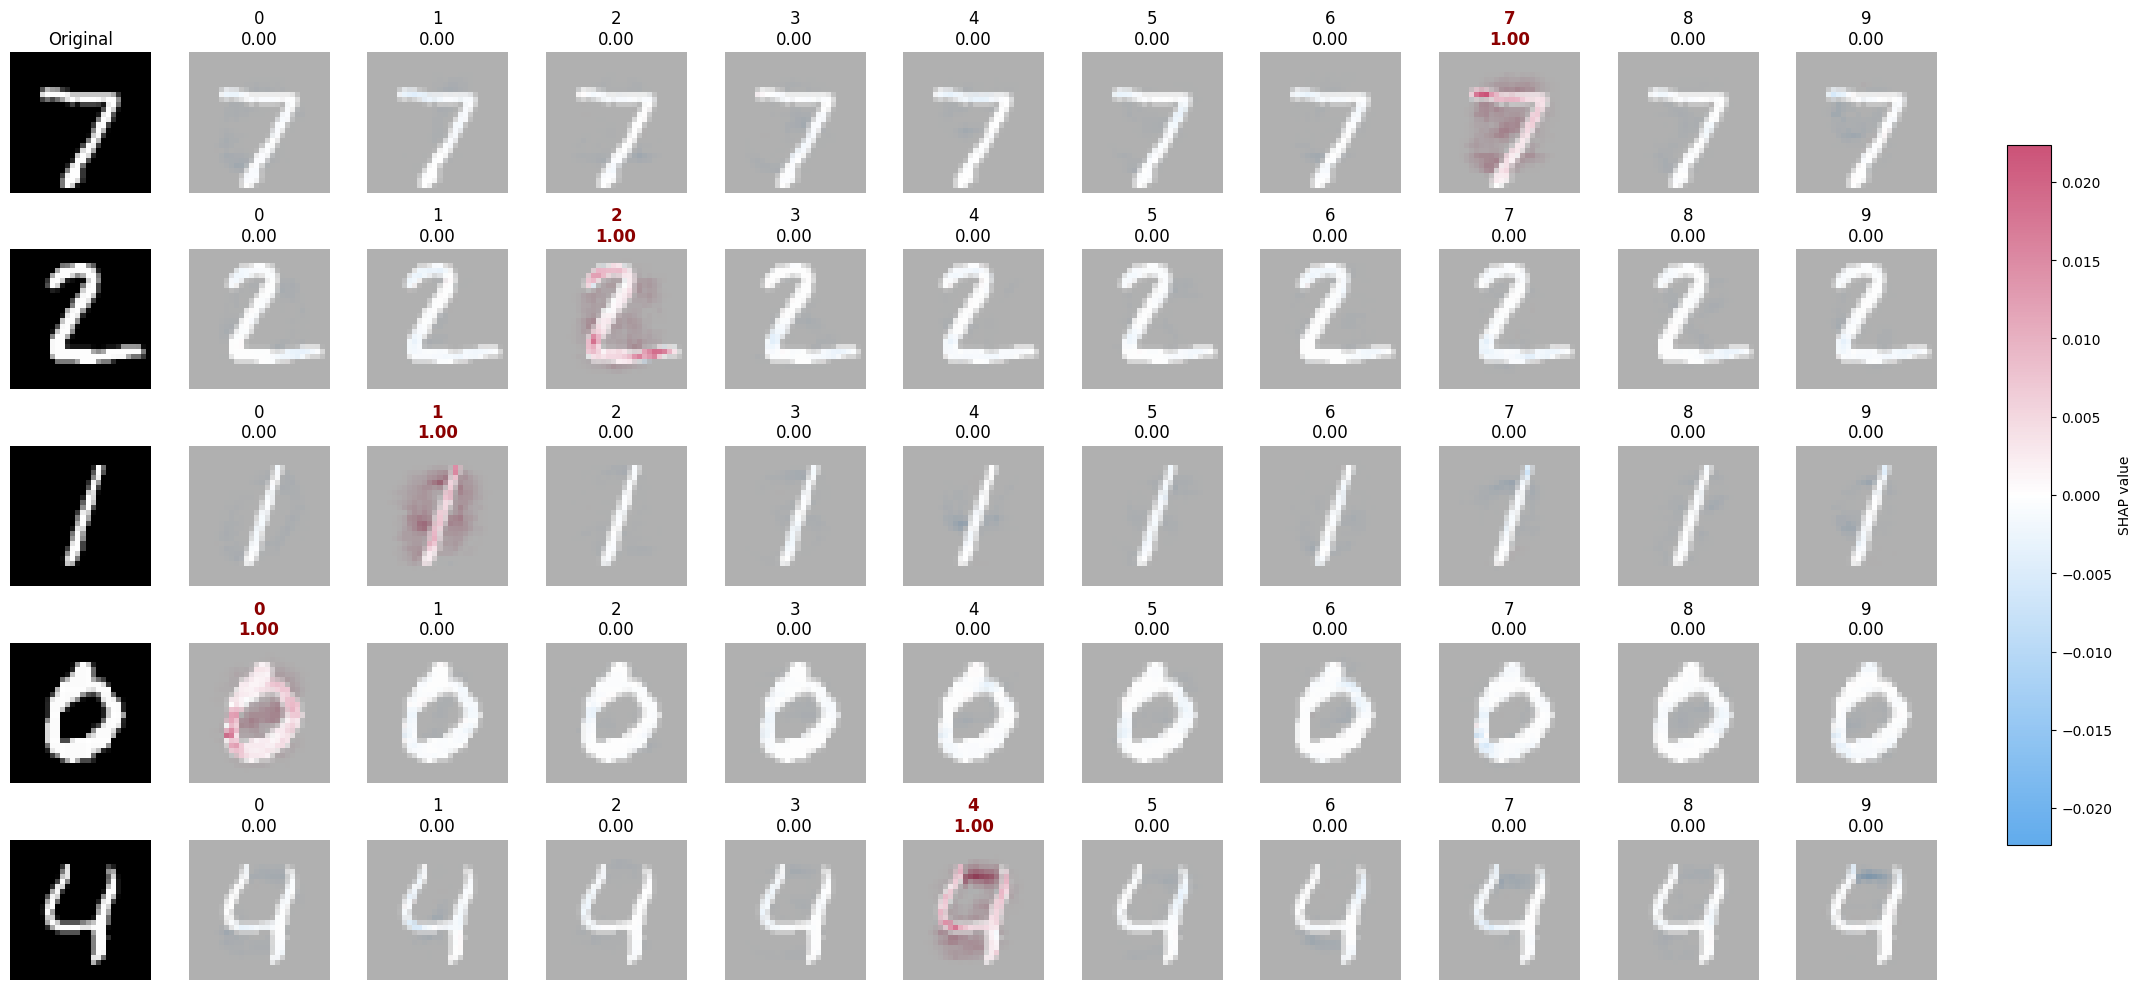

In [15]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# Définir la colormap SHAP (bleu → blanc → rouge)
shap_cmap = mcolors.LinearSegmentedColormap.from_list(
    "shap",
    ["#1e88e5", "white", "#b6093e"]
)

# bornes symétriques autour de 0
m = np.max(np.abs(shap_values))  # global max

fig, axes = plt.subplots(n_samples, n_classes+1, figsize=(2*(n_classes+1), 2*n_samples))

for i in range(n_samples):         # ligne = image
    # --- première colonne : chiffre original ---
    _ = axes[i, 0].imshow(x_test[i].squeeze(), cmap="gray")
    _ = axes[i, 0].axis("off")
    if i == 0:
        _ = axes[i, 0].set_title("Original")

    # --- colonnes suivantes : SHAP values ---
    for j in range(n_classes):
        sv = shap_values[i, :, :, 0, j]

        _ = axes[i, j+1].imshow(x_test[i].squeeze(), cmap="gray")
        im = axes[i, j+1].imshow(sv, cmap=shap_cmap, alpha=0.7,
                                 vmin=-m, vmax=+m)
        _ = axes[i, j+1].axis("off")

        # Ajouter la proba en titre
        prob = probs[i, j]
        title = f"{j}\n{prob:.2f}"
        if j == pred_classes[i]:
            # mettre en évidence la classe prédite
            _ = axes[i, j+1].set_title(title, color="darkred", fontweight="bold")
        else:
            _ = axes[i, j+1].set_title(title)

# Ajouter une colorbar partagée
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  
fig.colorbar(im, cax=cbar_ax, orientation="vertical", label="SHAP value")

plt.tight_layout(rect=[0, 0, 0.9, 1])  
plt.show()


In [16]:
i = 0
class_ids = [2, 7]

for cls in class_ids:
    sv_sum = shap_values[i, :, :, 0, cls].sum()
    expected_value = explainer.expected_value[cls]
    prob_reconstructed = expected_value + sv_sum
    prob_model = probs[i, cls]

    print(f"--- Classe {cls} ---")
    print(f"Somme SHAP = {sv_sum:.4f}")
    print(f"Expected value = {expected_value:.4f}")
    print(f"Proba (reconstruite) = {prob_reconstructed:.4f}")
    print(f"Proba (modèle)       = {prob_model:.4f}")
    print()


--- Classe 2 ---
Somme SHAP = -0.0801
Expected value = 0.0801
Proba (reconstruite) = 0.0000
Proba (modèle)       = 0.0000

--- Classe 7 ---
Somme SHAP = 0.8849
Expected value = 0.1151
Proba (reconstruite) = 1.0000
Proba (modèle)       = 1.0000



/tmp/ipykernel_686425/3758712975.py:58: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])


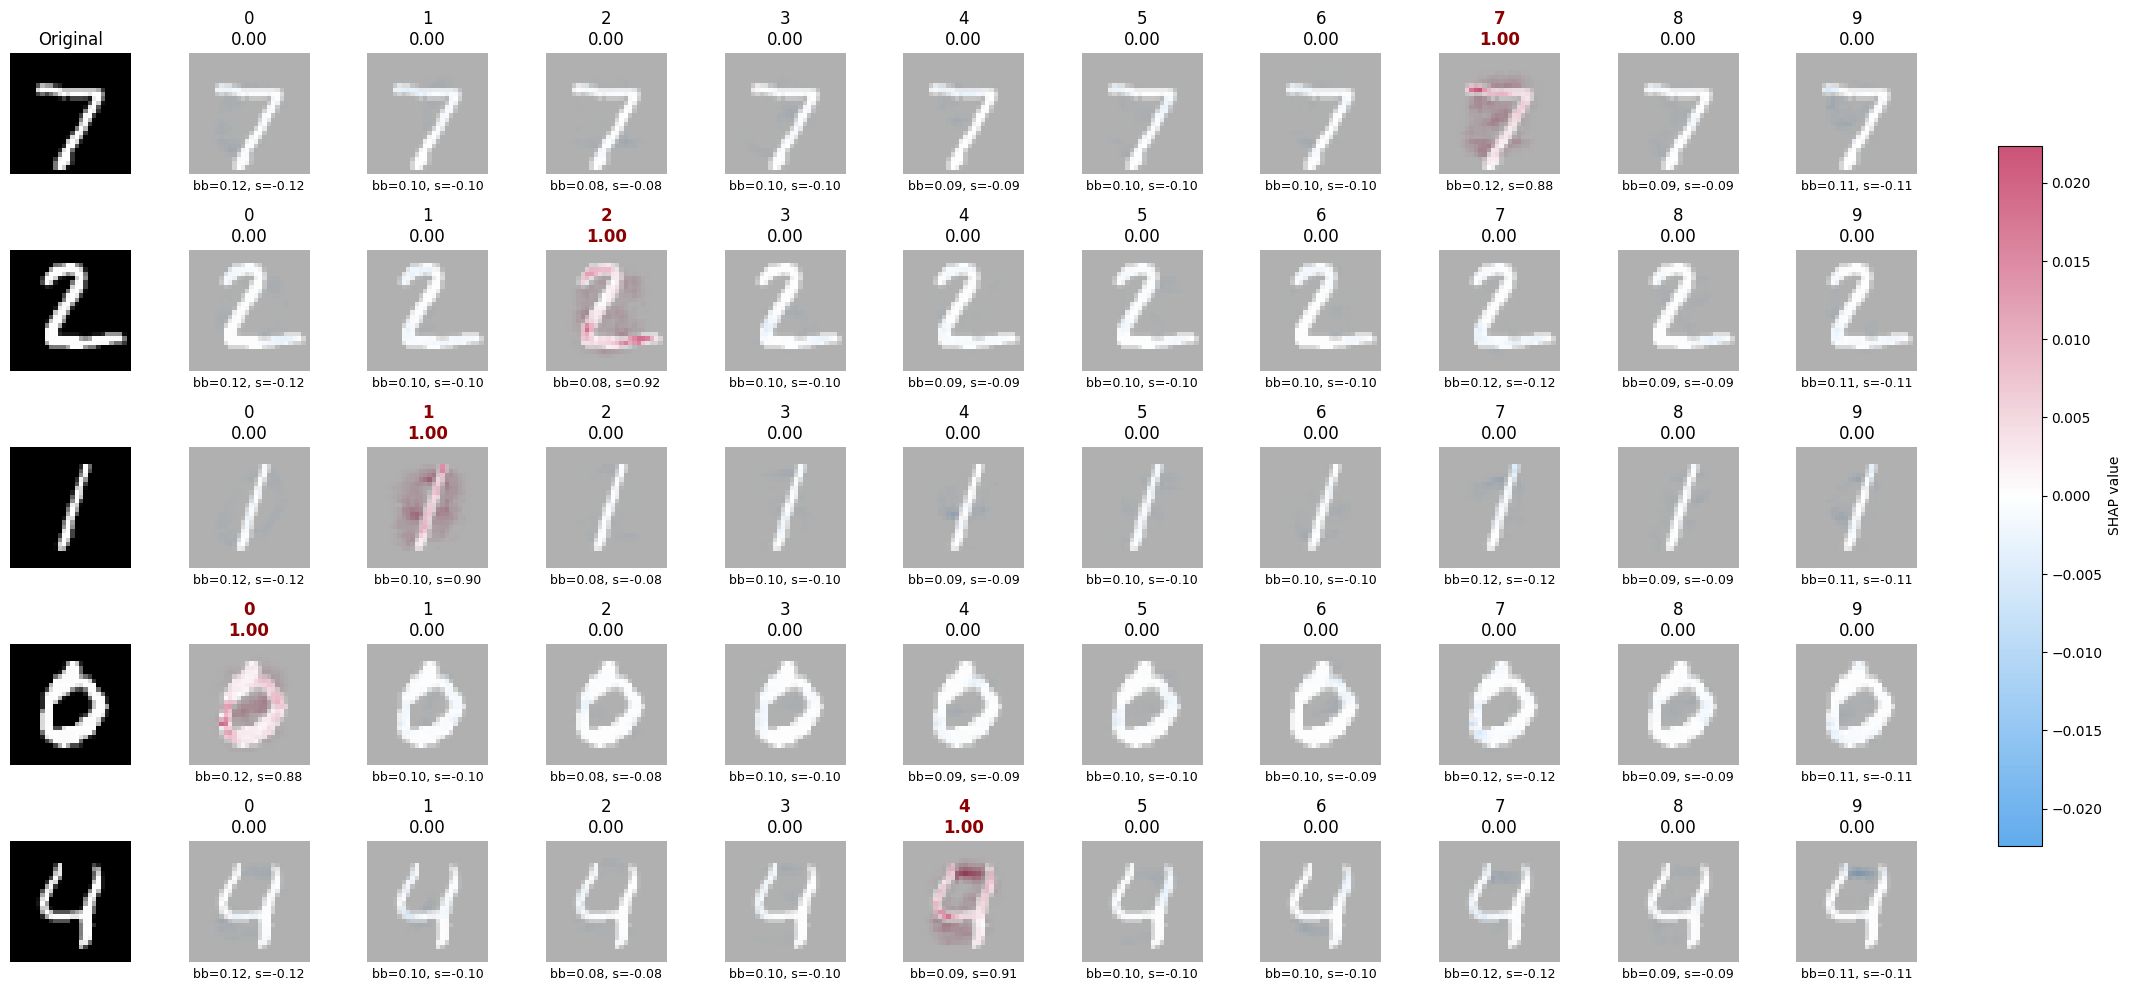

In [17]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# Définir la colormap SHAP (bleu → blanc → rouge)
shap_cmap = mcolors.LinearSegmentedColormap.from_list(
    "shap",
    ["#1e88e5", "white", "#b6093e"]
)

# bornes symétriques autour de 0
m = np.max(np.abs(shap_values))  # global max

fig, axes = plt.subplots(n_samples, n_classes+1, figsize=(2*(n_classes+1), 2*n_samples))

for i in range(n_samples):         # ligne = image
    # --- première colonne : chiffre original ---
    _ = axes[i, 0].imshow(x_test[i].squeeze(), cmap="gray")
    _ = axes[i, 0].axis("off")
    if i == 0:
        _ = axes[i, 0].set_title("Original")

    # --- colonnes suivantes : SHAP values ---
    for j in range(n_classes):
        sv = shap_values[i, :, :, 0, j]

        _ = axes[i, j+1].imshow(x_test[i].squeeze(), cmap="gray")
        im = axes[i, j+1].imshow(sv, cmap=shap_cmap, alpha=0.7,
                                 vmin=-m, vmax=+m)
        _ = axes[i, j+1].axis("off")

        # Proba prédite
        prob = probs[i, j]

        # Décomposition additive
        sv_sum = sv.sum()
        base_val = explainer.expected_value[j]
        reconstructed = base_val + sv_sum

        # Ajouter la proba en titre
        title = f"{j}\n{prob:.2f}"
        if j == pred_classes[i]:
            _ = axes[i, j+1].set_title(title, color="darkred", fontweight="bold")
        else:
            _ = axes[i, j+1].set_title(title)

        # Ajouter base_value et somme SHAP en bas de la case
        text = f"bb={base_val:.2f}, s={sv_sum:.2f}"
        _ = axes[i, j+1].text(0.5, -0.05, text,
                              fontsize=9, ha="center", va="top",
                              transform=axes[i, j+1].transAxes)


# Ajouter une colorbar partagée
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  
fig.colorbar(im, cax=cbar_ax, orientation="vertical", label="SHAP value")

plt.tight_layout(rect=[0, 0, 0.9, 1])  
plt.show()


In [18]:
from tensorflow.keras.models import Model

# suppose que la dernière couche de ton modèle est une Dense(10, activation="softmax")
# alors l'avant-dernière est Dense(10) sans activation
model_logits = Model(inputs=model.input, outputs=model.layers[-2].output)

logits = model_logits.predict(x_test[i:i+1], verbose=0)[0]
print("Logits modèle :", logits)

for cls in [2, 7]:
    sv_sum = shap_values[i, :, :, 0, cls].sum()
    logit_reconstructed = explainer.expected_value[cls] + sv_sum
    print(f"Classe {cls} | logit shap {logit_reconstructed:.4f} | logit modèle {logits[cls]:.4f}")


Logits modèle : [0.         0.         0.         1.4353532  7.1529446  4.6379604
 0.         5.734711   0.         0.         2.7540321  0.
 3.436913   0.         0.         0.         1.2752354  0.
 0.         0.         0.         0.         0.         5.763237
 0.         0.         2.7041883  4.8612537  0.         0.
 0.         0.         0.         3.528919   0.         0.09302375
 0.         3.3163135  0.         2.7893078  0.         0.
 0.         0.         0.         0.         0.         0.
 2.8258471  0.         0.         0.         0.         3.9732547
 5.800959   3.025613   0.         1.9760103  0.         0.
 0.         3.4789317  0.         0.         1.3350593  0.
 1.6813023  1.8237413  0.         0.         0.         0.
 0.         0.         0.5297712  0.         0.         4.759885
 0.         0.         0.         3.636154   0.6609805  3.4539416
 0.         0.         0.         0.         0.         0.
 0.         2.2011793  0.         0.         0.         0.

In [19]:
import tensorflow as tf
import numpy as np

def integrated_gradients(model, x, target_class_idx, baseline=None, steps=50):
    """
    Calcule les Integrated Gradients pour une seule image x.
    
    model : modèle Keras avec softmax en sortie
    x : image (shape (28,28,1))
    target_class_idx : index de la classe cible
    baseline : image de référence (par défaut image nulle)
    steps : nombre d'interpolations
    """
    if baseline is None:
        baseline = np.zeros_like(x).astype(np.float32)
    x = x.astype(np.float32)

    # interpolation entre baseline et image
    interpolated = np.array([baseline + (float(k)/steps)*(x - baseline) for k in range(steps+1)])
    interpolated = tf.convert_to_tensor(interpolated)

    with tf.GradientTape() as tape:
        tape.watch(interpolated)
        preds = model(interpolated)  # (steps+1, n_classes)
        probs = preds[:, target_class_idx]

    grads = tape.gradient(probs, interpolated).numpy()  # (steps+1, 28,28,1)

    # average of the gradients x (image - baseline)
    avg_grads = grads.mean(axis=0)
    integrated = (x - baseline) * avg_grads
    return integrated


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
True label = 7, Predicted = 7, prob = 1.000


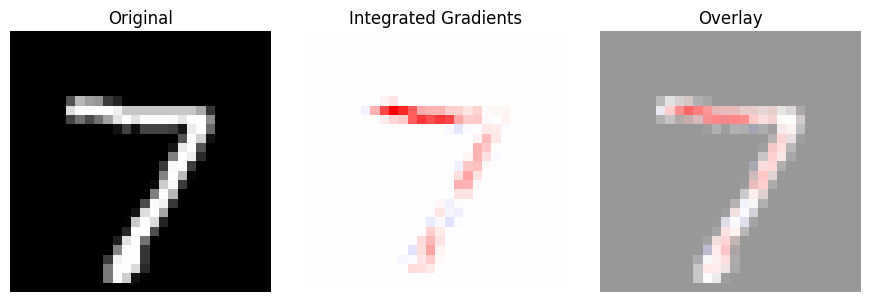

In [20]:
import matplotlib.pyplot as plt
import numpy as np

i = 0  # index de l'image testée
img = x_test[i]

pred = model.predict(img[np.newaxis, ...])
pred_class = np.argmax(pred)

print(f"True label = {y_test[i]}, Predicted = {pred_class}, prob = {pred[0,pred_class]:.3f}")

# calcul des Integrated Gradients pour la classe prédite
ig = integrated_gradients(model, img, pred_class, steps=50)

# bornes symétriques autour de 0
m = np.max(np.abs(ig))

plt.figure(figsize=(9,3))
plt.subplot(1,3,1)
plt.imshow(img.squeeze(), cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(ig.squeeze(), cmap="bwr", vmin=-m, vmax=m)
plt.title("Integrated Gradients")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(img.squeeze(), cmap="gray")
plt.imshow(ig.squeeze(), cmap="bwr", alpha=0.6, vmin=-m, vmax=m)
plt.title("Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()


### [A.2] A reusable class

In [21]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import shap

class ShapVisualizer:
    """
    Visualize SHAP values for CNN models on image data.

    This class overlays SHAP attribution maps on grayscale images 
    and displays, for each sample and each class:
    - the original image,
    - the SHAP heatmap,
    - the predicted probability,
    - the additive decomposition (base value + sum of SHAP, and reconstructed value).

    Parameters
    ----------
    model : keras.Model
        Trained Keras model with softmax output.
    explainer : shap.DeepExplainer
        SHAP explainer fitted on a background dataset.
    x_explain : np.ndarray
        Images to explain, shape (n_samples, H, W, 1).

    Attributes
    ----------
    shap_values : np.ndarray
        SHAP values of shape (n_samples, H, W, 1, n_classes).
    probs : np.ndarray
        Model predicted probabilities, shape (n_samples, n_classes).
    pred_classes : np.ndarray
        Indices of predicted classes, shape (n_samples,).
    n_samples : int
        Number of explained images.
    n_classes : int
        Number of output classes.
    """

    def __init__(self, model, explainer, x_explain):
        self.model = model
        self.explainer = explainer
        self.x_explain = x_explain

        # Compute SHAP values, predictions, classes
        self.shap_values = explainer.shap_values(x_explain)
        self.probs = model.predict(x_explain, verbose=0)
        self.pred_classes = np.argmax(self.probs, axis=1)

        # Dimensions
        self.n_samples = x_explain.shape[0]
        self.n_classes = self.probs.shape[1]

        # Define SHAP colormap (blue → white → red)
        self.shap_cmap = mcolors.LinearSegmentedColormap.from_list(
            "shap",
            ["#1e88e5", "white", "#b6093e"]
        )

    def plot(self):
        """Plot SHAP overlays for the explained images."""
        m = np.max(np.abs(self.shap_values))  # global symmetric scale

        fig, axes = plt.subplots(
            self.n_samples, self.n_classes+1,
            figsize=(2*(self.n_classes+1), 2*self.n_samples)
        )

        for i in range(self.n_samples):  # each row = one image
            # First column: original image
            _ = axes[i, 0].imshow(self.x_explain[i].squeeze(), cmap="gray")
            _ = axes[i, 0].axis("off")
            if i == 0:
                _ = axes[i, 0].set_title("Original")

            # Columns: SHAP heatmaps
            for j in range(self.n_classes):
                sv = self.shap_values[i, :, :, 0, j]
                _ = axes[i, j+1].imshow(self.x_explain[i].squeeze(), cmap="gray")
                im = axes[i, j+1].imshow(
                    sv, cmap=self.shap_cmap, alpha=0.7, vmin=-m, vmax=+m
                )
                _ = axes[i, j+1].axis("off")

                # Probability and decomposition
                prob = self.probs[i, j]
                sv_sum = sv.sum()
                base_val = self.explainer.expected_value[j]
                reconstructed = base_val + sv_sum

                # Title: class + probability
                title = f"{j}\n{prob:.2f}"
                if j == self.pred_classes[i]:
                    _ = axes[i, j+1].set_title(
                        title, color="darkred", fontweight="bold"
                    )
                else:
                    _ = axes[i, j+1].set_title(title)

                # Bottom text: base + SHAP sum + reconstructed
                text = f"bv={base_val:.2f}, s={sv_sum:.2f}"
                _ = axes[i, j+1].text(
                    0.5, -0.05, text,
                    fontsize=9, ha="center", va="top",
                    transform=axes[i, j+1].transAxes
                )

        # Shared colorbar
        cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
        fig.colorbar(im, cax=cbar_ax, orientation="vertical", label="SHAP value")

        plt.tight_layout(rect=[0, 0, 0.9, 1])
        plt.show()


background.shape=(200, 28, 28, 1)


/tmp/ipykernel_686425/2438476596.py:112: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])


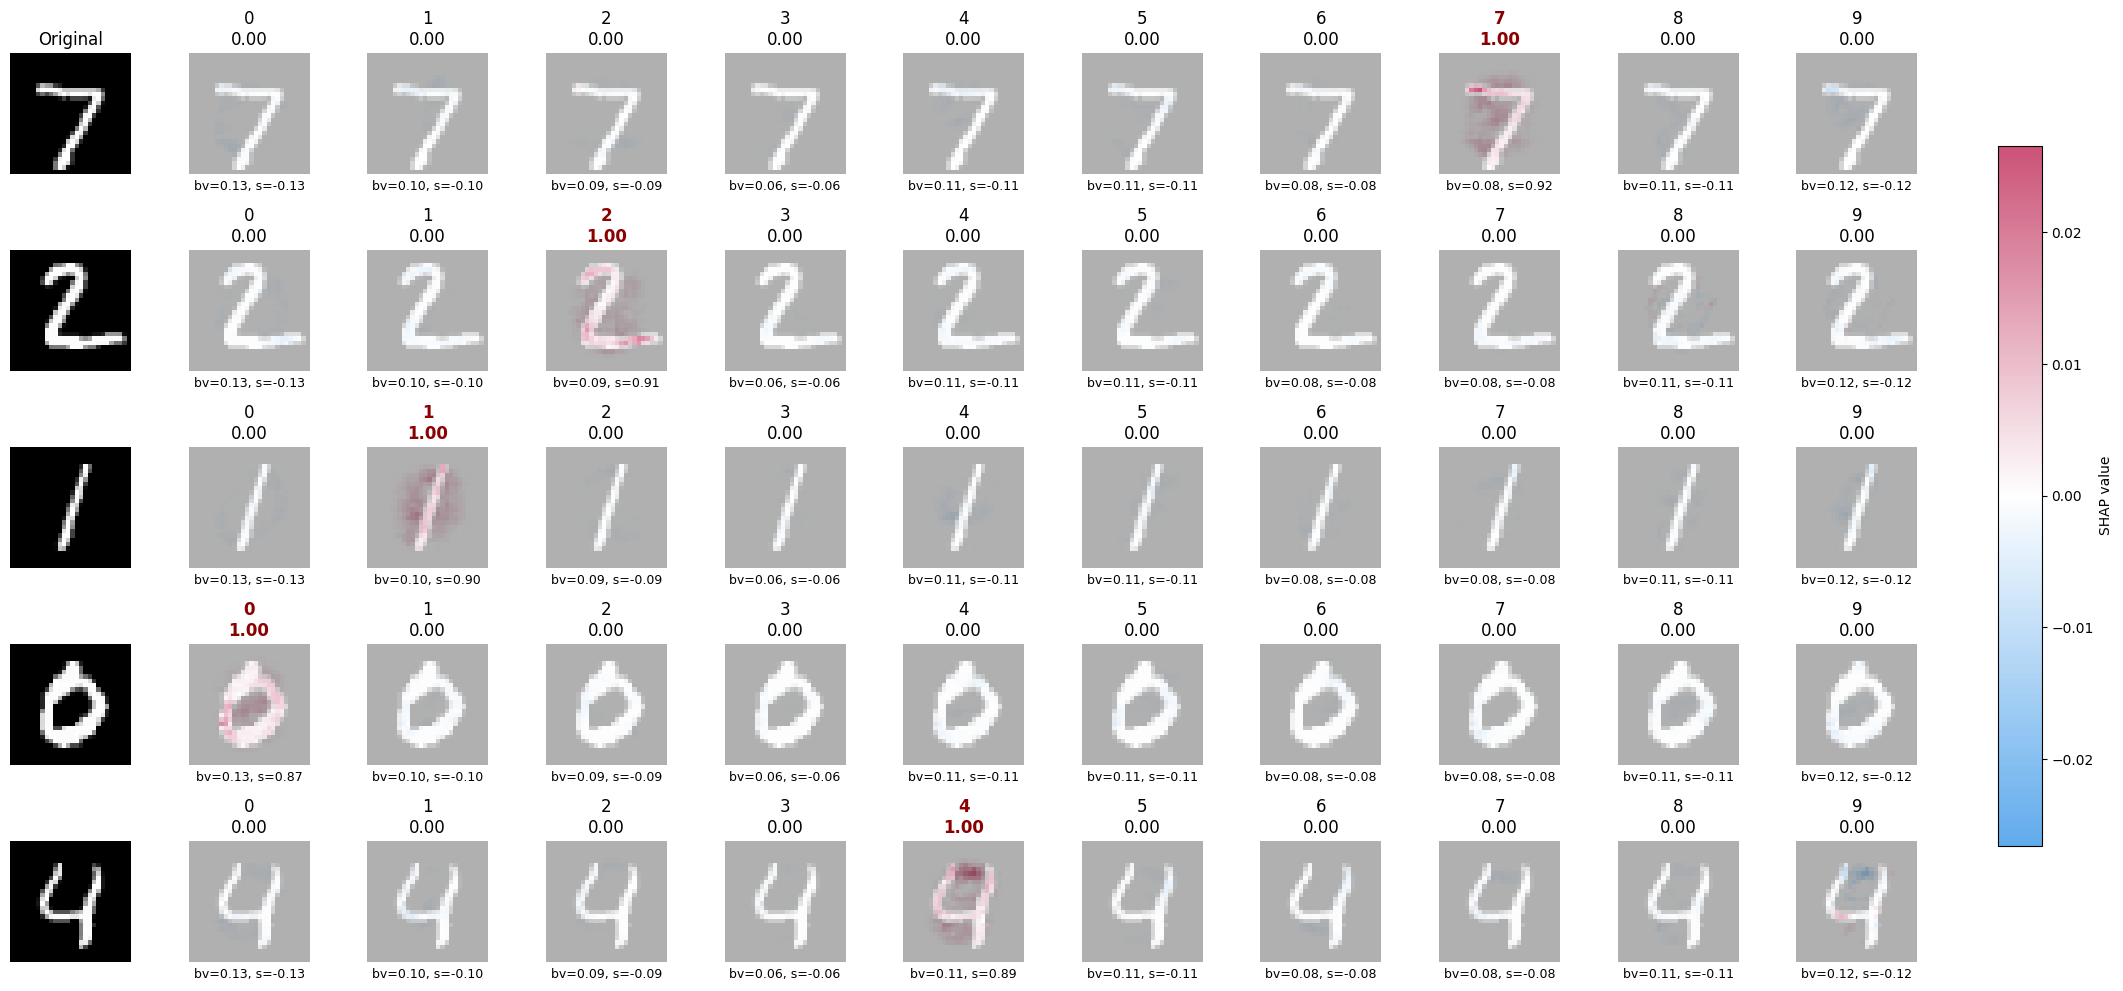

In [22]:
# Random background (used only as baseline)
background = x_train[np.random.choice(x_train.shape[0], 200, replace=False)]
print(f"{background.shape=}")

# Explainer built on this background
explainer = shap.DeepExplainer(model, background)

# Only pass the images you want to explain
visu = ShapVisualizer(model, explainer, x_test[:5])
visu.plot()


In [23]:
t4pPC.end()

**End at:** Sunday 22 November 2026, 15:58:41  
**Duration:** 00:02:37 759ms